In [1]:
# Colab setup — mount Drive and install packages
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

if IS_COLAB:
    %pip install -q transformers datasets accelerate

Mounted at /content/drive


In [2]:
from pathlib import Path

if IS_COLAB:
    PROJECT_ROOT = Path("/content/drive/MyDrive/thesis_stage2")
else:
    PROJECT_ROOT = Path(".")

MODELS_DIR    = PROJECT_ROOT / "models"
RESULTS_DIR   = PROJECT_ROOT / "results"

# === CHANGE THESE TWO VARIABLES BETWEEN RUNS ===
VARIANT       = "v1_balanced"   # "v1_balanced" or "v1_rebalanced"
CLASS_WEIGHTED = False          # True or False

# === HYPERPARAMETERS (mirror chapter 4.4.4) ===
MODEL_NAME    = "roberta-base"
SEED          = 42
MAX_LEN       = 512
LR            = 2e-5
WEIGHT_DECAY  = 0.01
EPOCHS        = 10
BATCH_TRAIN   = 16
BATCH_EVAL    = 32
WARMUP_RATIO  = 0.1
GRAD_CLIP     = 1.0
EARLY_STOP    = 3

# === DATASET CHOICE ===
DATASET = "therapistqa"   # was implicitly "patternreframe_aug"

if DATASET == "therapistqa":
    TRAIN_CSV = PROJECT_ROOT / "therapistqa_train.csv"
    VAL_CSV   = PROJECT_ROOT / "therapistqa_val.csv"
    TEST_CSV  = PROJECT_ROOT / "therapistqa_test.csv"
    TEXT_COL  = "patient_question"
    LABEL_COL = "dominant_distortion"
    RUN_TAG   = "tqa_binary"
elif DATASET == "patternreframe_aug":
    TRAIN_CSV = PROJECT_ROOT / f"patternreframe_train_aug_{VARIANT}.csv"
    VAL_CSV   = PROJECT_ROOT / f"patternreframe_val_aug_{VARIANT}.csv"
    TEST_CSV  = PROJECT_ROOT / f"patternreframe_test_aug_{VARIANT}.csv"
    TEXT_COL  = "thought"
    LABEL_COL = "pattern"
    RUN_TAG   = f"{VARIANT}{'_weighted' if CLASS_WEIGHTED else ''}"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR   = MODELS_DIR / f"binary_{DATASET}_{RUN_TAG}"

print(f"VARIANT:        {VARIANT}")
print(f"CLASS_WEIGHTED: {CLASS_WEIGHTED}")
print(f"RUN_TAG:        {RUN_TAG}")
print(f"Train: {TRAIN_CSV}")
print(f"Val:   {VAL_CSV}")
print(f"Test:  {TEST_CSV}")
print(f"Out:   {OUT_DIR}")

VARIANT:        v1_balanced
CLASS_WEIGHTED: False
RUN_TAG:        tqa_binary
Train: /content/drive/MyDrive/thesis_stage2/therapistqa_train.csv
Val:   /content/drive/MyDrive/thesis_stage2/therapistqa_val.csv
Test:  /content/drive/MyDrive/thesis_stage2/therapistqa_test.csv
Out:   /content/drive/MyDrive/thesis_stage2/models/binary_therapistqa_tqa_binary


In [3]:
# 1. Load splits and build binary labels
import pandas as pd


def load_split(path):
    df = pd.read_csv(path)
    df = df[[TEXT_COL, LABEL_COL]].copy()
    df["text"] = df[TEXT_COL].astype(str)
    df["label"] = (df[LABEL_COL] != "No Distortion").astype(int)
    return df[["text", "label", LABEL_COL]].rename(columns={LABEL_COL: "category"})


train_df = load_split(TRAIN_CSV)
val_df   = load_split(VAL_CSV)
test_df  = load_split(TEST_CSV)

print(f"Train: {len(train_df)} — labels: {train_df.label.value_counts().to_dict()}")
print(f"Val:   {len(val_df)} — labels: {val_df.label.value_counts().to_dict()}")
print(f"Test:  {len(test_df)} — labels: {test_df.label.value_counts().to_dict()}")


Train: 1768 — labels: {1: 1116, 0: 652}
Val:   379 — labels: {1: 239, 0: 140}
Test:  379 — labels: {1: 239, 0: 140}


In [4]:
# 2. Tokeniser and model
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "No Distortion", 1: "Distorted"},
    label2id={"No Distortion": 0, "Distorted": 1},
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [6]:
# 3. Tokenise the splits
from datasets import Dataset


def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)


ds_train = Dataset.from_pandas(train_df).map(tokenize, batched=True)
ds_val   = Dataset.from_pandas(val_df).map(tokenize, batched=True)
ds_test  = Dataset.from_pandas(test_df).map(tokenize, batched=True)

# Drop non-tensor columns (the Trainer will complain otherwise)
ds_train = ds_train.remove_columns(["text"])
ds_val   = ds_val.remove_columns(["text"])
ds_test_for_eval = ds_test.remove_columns(["text"])

Map:   0%|          | 0/1768 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

In [7]:
# 4. Metrics function
import numpy as np
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", pos_label=1, zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision_distorted": p,
        "recall_distorted": r,
        "f1_distorted": f1,
        "f1_weighted": f1_score(labels, preds, average="weighted", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
    }

In [8]:
# Class-weighted trainer subclass. If CLASS_WEIGHTED is False the trainer
# behaves like the standard one — class_weights stays None and we fall back
# to vanilla cross-entropy.
import torch
import torch.nn as nn
from transformers import Trainer

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weight = self.class_weights.to(outputs.logits.device) if self.class_weights is not None else None
        loss = nn.CrossEntropyLoss(weight=weight)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


# Compute class weights from the training-set label counts. Inverse frequency,
# normalised so the weights sum to the number of classes — the same formula
# sklearn's compute_class_weight uses with class_weight="balanced".
if CLASS_WEIGHTED:
    counts = train_df["label"].value_counts().sort_index()
    n_nd        = int(counts.loc[0])
    n_distorted = int(counts.loc[1])
    total = n_nd + n_distorted
    w_nd        = total / (2 * n_nd)
    w_distorted = total / (2 * n_distorted)
    class_weights = torch.tensor([w_nd, w_distorted], dtype=torch.float)
    print(f"Train counts: ND={n_nd}, Distorted={n_distorted}")
    print(f"Class weights: ND={w_nd:.3f}, Distorted={w_distorted:.3f}")
else:
    class_weights = None
    print("Unweighted training (class_weights=None).")

Unweighted training (class_weights=None).


In [9]:
# 5. Trainer and training
from transformers import (
    DataCollatorWithPadding, EarlyStoppingCallback, TrainingArguments,
)

training_args = TrainingArguments(
    output_dir="/content/trainer_tmp",
    num_train_epochs=EPOCHS,
    learning_rate=LR,
    weight_decay=WEIGHT_DECAY,
    per_device_train_batch_size=BATCH_TRAIN,
    per_device_eval_batch_size=BATCH_EVAL,
    warmup_ratio=WARMUP_RATIO,
    max_grad_norm=GRAD_CLIP,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEED,
    report_to=[],
    logging_steps=50,
)

trainer = WeightedTrainer(
    class_weights=class_weights,
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOP)],
)

trainer.train()

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Distorted,Recall Distorted,F1 Distorted,F1 Weighted,F1 Macro
1,0.637884,0.547938,0.704485,0.763485,0.769874,0.766667,0.704038,0.681894
2,0.523275,0.562499,0.709763,0.747126,0.815900,0.780000,0.703773,0.676822
3,0.437937,0.507613,0.730871,0.752768,0.853556,0.800000,0.721951,0.694355
4,0.318985,0.623324,0.722955,0.776860,0.786611,0.781705,0.722319,0.701322
5,0.199963,0.970634,0.725594,0.754717,0.836820,0.793651,0.718627,0.692101
6,0.196798,1.247933,0.725594,0.747253,0.853556,0.796875,0.715742,0.687055
7,0.086501,1.468545,0.712401,0.775424,0.765690,0.770526,0.713017,0.692684


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=777, training_loss=0.3420195114658606, metrics={'train_runtime': 1294.6721, 'train_samples_per_second': 13.656, 'train_steps_per_second': 0.857, 'total_flos': 2980534368448800.0, 'train_loss': 0.3420195114658606, 'epoch': 7.0})

In [10]:
# 6. Test-set evaluation
test_metrics = trainer.evaluate(ds_test_for_eval)
print("Test metrics:")
for k, v in test_metrics.items():
    print(f"  {k}: {v}")

Test metrics:
  eval_loss: 0.5614275336265564
  eval_accuracy: 0.7757255936675461
  eval_precision_distorted: 0.8104838709677419
  eval_recall_distorted: 0.8410041841004184
  eval_f1_distorted: 0.8254620123203286
  eval_f1_weighted: 0.7740738306864575
  eval_f1_macro: 0.7559044378944817
  eval_runtime: 11.338
  eval_samples_per_second: 33.427
  eval_steps_per_second: 1.058
  epoch: 7.0


In [12]:
# 7. Predictions and per-category recall
from torch.nn.functional import softmax
from sklearn.metrics import classification_report, confusion_matrix

pred_out = trainer.predict(ds_test_for_eval)
probs = softmax(torch.tensor(pred_out.predictions), dim=-1).numpy()

out_df = test_df.copy()
out_df["pred"] = np.argmax(pred_out.predictions, axis=-1)
out_df["prob_distorted"] = probs[:, 1]

# Per-category recall: of records with each long-form pattern, what fraction
# did the binary detector recover correctly.
per_category_recall = {}
for cat in sorted(out_df["category"].unique()):
    sub = out_df[out_df["category"] == cat]
    if cat == "No Distortion":
        per_category_recall[cat] = float((sub["pred"] == 0).mean())
    else:
        per_category_recall[cat] = float((sub["pred"] == 1).mean())

print("Per-category recall:")
for cat, rec in per_category_recall.items():
    print(f"  {cat:60s}  {rec:.4f}")

Per-category recall:
  All-or-nothing thinking                                       0.8667
  Emotional Reasoning                                           0.9000
  Fortune-telling                                               0.8095
  Labeling                                                      0.8400
  Magnification                                                 0.9310
  Mental filter                                                 0.7778
  Mind Reading                                                  0.7778
  No Distortion                                                 0.6643
  Overgeneralization                                            0.7778
  Personalization                                               0.9130
  Should statements                                             0.8750


In [13]:
# 8. Save results
import json

cm = confusion_matrix(out_df["label"], out_df["pred"])
report = classification_report(
    out_df["label"], out_df["pred"],
    target_names=["No Distortion", "Distorted"],
    digits=4, output_dict=True, zero_division=0,
)

results = {
    "variant": VARIANT,
    "test_metrics": test_metrics,
    "confusion_matrix": cm.tolist(),
    "classification_report": report,
    "per_category_recall": per_category_recall,
    "n_train": len(train_df),
    "n_val": len(val_df),
    "n_test": len(test_df),
}

metrics_path = RESULTS_DIR / f"binary_patternreframe_{RUN_TAG}_test_metrics.json"
preds_path   = RESULTS_DIR / f"binary_patternreframe_{RUN_TAG}_test_predictions.csv"

with open(metrics_path, "w") as f:
    json.dump(results, f, indent=2)
out_df.to_csv(preds_path, index=False)

trainer.save_model(str(OUT_DIR / "best"))
tokenizer.save_pretrained(str(OUT_DIR / "best"))

print(f"Saved metrics to {metrics_path}")
print(f"Saved predictions to {preds_path}")
print(f"Saved model to {OUT_DIR / 'best'}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved metrics to /content/drive/MyDrive/thesis_stage2/results/binary_patternreframe_tqa_binary_test_metrics.json
Saved predictions to /content/drive/MyDrive/thesis_stage2/results/binary_patternreframe_tqa_binary_test_predictions.csv
Saved model to /content/drive/MyDrive/thesis_stage2/models/binary_therapistqa_tqa_binary/best


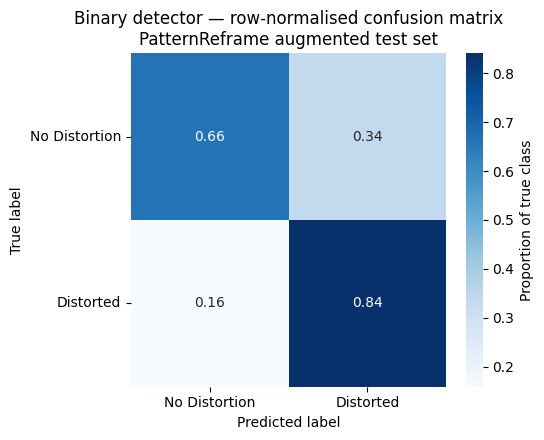

Saved figure to /content/drive/MyDrive/thesis_stage2/results/binary_patternreframe_tqa_binary_confusion_matrix.png


In [14]:
# 9. Confusion matrix plot
import matplotlib.pyplot as plt
import seaborn as sns

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm_norm,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=["No Distortion", "Distorted"],
    yticklabels=["No Distortion", "Distorted"],
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Binary detector — row-normalised confusion matrix\nPatternReframe augmented test set")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()

fig_path = RESULTS_DIR / f"binary_patternreframe_{RUN_TAG}_confusion_matrix.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {fig_path}")

In [16]:
# Cross-evaluation: TQA-trained binary detector on PatternReframe augmented test
import pandas as pd
import numpy as np
import torch
from torch.nn.functional import softmax
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, accuracy_score,
)

# === Load the PR augmented test split ===
# Use v1_balanced (the canonical augmented split). Either rebalanced or
# balanced would work — the test set is identical between them.
PR_TEST = PROJECT_ROOT / "patternreframe_test_aug_v1_balanced.csv"
print(f"Loading PR augmented test from: {PR_TEST}")

pr = pd.read_csv(PR_TEST)
pr["text"]    = pr["thought"].astype(str)
pr["label"]   = (pr["pattern"] != "No Distortion").astype(int)
pr["category"] = pr["pattern"]
print(f"PR-aug test: {len(pr)} rows, "
      f"label distribution: {pr['label'].value_counts().to_dict()}")

# === Inference ===
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device).eval()

preds, probs = [], []
BS = 32
with torch.no_grad():
    for i in range(0, len(pr), BS):
        batch_texts = pr["text"].iloc[i:i+BS].tolist()
        enc = tokenizer(
            batch_texts, truncation=True, max_length=MAX_LEN,
            padding=True, return_tensors="pt"
        ).to(device)
        logits = model(**enc).logits
        p = softmax(logits, dim=-1).cpu().numpy()
        preds.extend(np.argmax(p, axis=-1).tolist())
        probs.extend(p[:, 1].tolist())

pr_eval = pr.copy()
pr_eval["pred"]            = preds
pr_eval["prob_distorted"]  = probs

# === Headline metrics ===
print("\n=== Cross-eval: TQA binary detector on PR augmented test ===")
print(f"Accuracy:    {accuracy_score(pr_eval['label'], pr_eval['pred']):.4f}")
print(f"Weighted F1: {f1_score(pr_eval['label'], pr_eval['pred'], average='weighted'):.4f}")
print(f"Macro F1:    {f1_score(pr_eval['label'], pr_eval['pred'], average='macro'):.4f}")
print()
print(classification_report(
    pr_eval["label"], pr_eval["pred"],
    target_names=["No Distortion", "Distorted"],
    digits=4, zero_division=0,
))
print("Confusion matrix:")
print(confusion_matrix(pr_eval["label"], pr_eval["pred"]))

# === The shortcut diagnostic: are the mean confidences for D and ND different? ===
nd_mask = pr_eval["label"] == 0
mean_prob_nd = pr_eval.loc[nd_mask,  "prob_distorted"].mean()
mean_prob_d  = pr_eval.loc[~nd_mask, "prob_distorted"].mean()
nd_called_d  = (pr_eval.loc[nd_mask, "pred"] == 1).mean()

print(f"\nOf the {nd_mask.sum()} PR-aug ND records, {nd_called_d:.1%} were "
      f"predicted as Distorted.")
print(f"Mean prob_distorted on PR-aug ND records: {mean_prob_nd:.3f}")
print(f"Mean prob_distorted on PR-aug D records:  {mean_prob_d:.3f}")
print(f"Confidence gap (D - ND): {mean_prob_d - mean_prob_nd:+.3f}")
print(f"(A gap of ~0.00 indicates no real binary signal transferred. "
      f"A gap of +0.20 or more indicates substantial transfer.)")

# === Per-category recall on PR distortion categories ===
print("\nPer-category recall on PR-aug test:")
per_category = {}
for cat in sorted(pr_eval["category"].unique()):
    sub = pr_eval[pr_eval["category"] == cat]
    if cat == "No Distortion":
        per_category[cat] = float((sub["pred"] == 0).mean())
    else:
        per_category[cat] = float((sub["pred"] == 1).mean())
for cat, rec in per_category.items():
    print(f"  {cat:60s}  {rec:.4f}")

# === Compare to the equivalent on TQA test for context ===
# Use the previously-computed TQA test classification report, if you ran
# notebook cell 8 from the TQA training run.
print(
    "\nFor reference, compare these numbers against:"
    "\n  - The TQA binary detector's own TQA test F1 (in-distribution baseline)"
    "\n  - The PR-aug-trained binary detector's PR-aug test F1 (≈ 0.99, shortcut)"
)

Loading PR augmented test from: /content/drive/MyDrive/thesis_stage2/patternreframe_test_aug_v1_balanced.csv
PR-aug test: 7488 rows, label distribution: {1: 6807, 0: 681}

=== Cross-eval: TQA binary detector on PR augmented test ===
Accuracy:    0.5156
Weighted F1: 0.6170
Macro F1:    0.3838

               precision    recall  f1-score   support

No Distortion     0.0595    0.2922    0.0989       681
    Distorted     0.8837    0.5380    0.6688      6807

     accuracy                         0.5156      7488
    macro avg     0.4716    0.4151    0.3838      7488
 weighted avg     0.8087    0.5156    0.6170      7488

Confusion matrix:
[[ 199  482]
 [3145 3662]]

Of the 681 PR-aug ND records, 70.8% were predicted as Distorted.
Mean prob_distorted on PR-aug ND records: 0.683
Mean prob_distorted on PR-aug D records:  0.538
Confidence gap (D - ND): -0.145
(A gap of ~0.00 indicates no real binary signal transferred. A gap of +0.20 or more indicates substantial transfer.)

Per-category rec